# Wine quality prediction

Midterm project - ML Zoomcamp 2026

Wine quality is usually rated by expert tasters, which is slow and expensive. Lab measurements (acidity, sugar, sulphates, alcohol...) are cheap, so the idea is to predict if a wine is good (quality >= 7) using only those measurements. A winery could use this to decide which batches to send to the tasters.

Dataset: [Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality) from UCI (red and white vinho verde wines from Portugal).

It's a binary classification problem. I use ROC AUC as the metric because only ~20% of the wines are good.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, mutual_info_score, precision_score, recall_score
from xgboost import XGBClassifier

%matplotlib inline

## 1. Loading the data

There are two files, one for red and one for white wines, with the same columns (separated by `;`). I join them and add a `wine_type` column so I can use one model for both.

In [2]:
df_red = pd.read_csv('data/winequality-red.csv', sep=';')
df_white = pd.read_csv('data/winequality-white.csv', sep=';')

df_red['wine_type'] = 'red'
df_white['wine_type'] = 'white'

df = pd.concat([df_red, df_white], ignore_index=True)
df.columns = df.columns.str.replace(' ', '_')

print(df.shape)
df.head()

(6497, 13)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


## 2. Data cleaning

In [3]:
df.dtypes

fixed_acidity           float64
volatile_acidity        float64
citric_acid             float64
residual_sugar          float64
chlorides               float64
free_sulfur_dioxide     float64
total_sulfur_dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
wine_type                   str
dtype: object

In [4]:
df.isnull().sum()

fixed_acidity           0
volatile_acidity        0
citric_acid             0
residual_sugar          0
chlorides               0
free_sulfur_dioxide     0
total_sulfur_dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
wine_type               0
dtype: int64

No missing values. Checking duplicates:

In [5]:
print('duplicated rows:', df.duplicated().sum())

duplicated rows: 1177


There are a lot of duplicated rows. I think they are different wines that just got the same measurements and score, so I keep them. The downside is that almost identical rows can end up in train and validation at the same time, so the scores could be a bit optimistic.

## 3. EDA

### Ranges of values

In [6]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
fixed_acidity,6497.0,7.215,1.296,3.800,6.400,7.000,7.700,15.900
volatile_acidity,6497.0,0.340,0.165,0.080,0.230,0.290,0.400,1.580
citric_acid,6497.0,0.319,0.145,0.000,0.250,0.310,0.390,1.660
residual_sugar,6497.0,5.443,4.758,0.600,1.800,3.000,8.100,65.800
chlorides,6497.0,0.056,0.035,0.009,0.038,0.047,0.065,0.611
free_sulfur_dioxide,6497.0,30.525,17.749,1.000,17.000,29.000,41.000,289.000
total_sulfur_dioxide,6497.0,115.745,56.522,6.000,77.000,118.000,156.000,440.000
density,6497.0,0.995,0.003,0.987,0.992,0.995,0.997,1.039
pH,6497.0,3.219,0.161,2.720,3.110,3.210,3.320,4.010
sulphates,6497.0,0.531,0.149,0.220,0.430,0.510,0.600,2.000


The scales are very different (density is around 1, total sulfur dioxide goes up to ~440), so I'll standardize the features for logistic regression. For trees it doesn't matter. Some features have long tails (residual sugar, chlorides, sulfur dioxide).

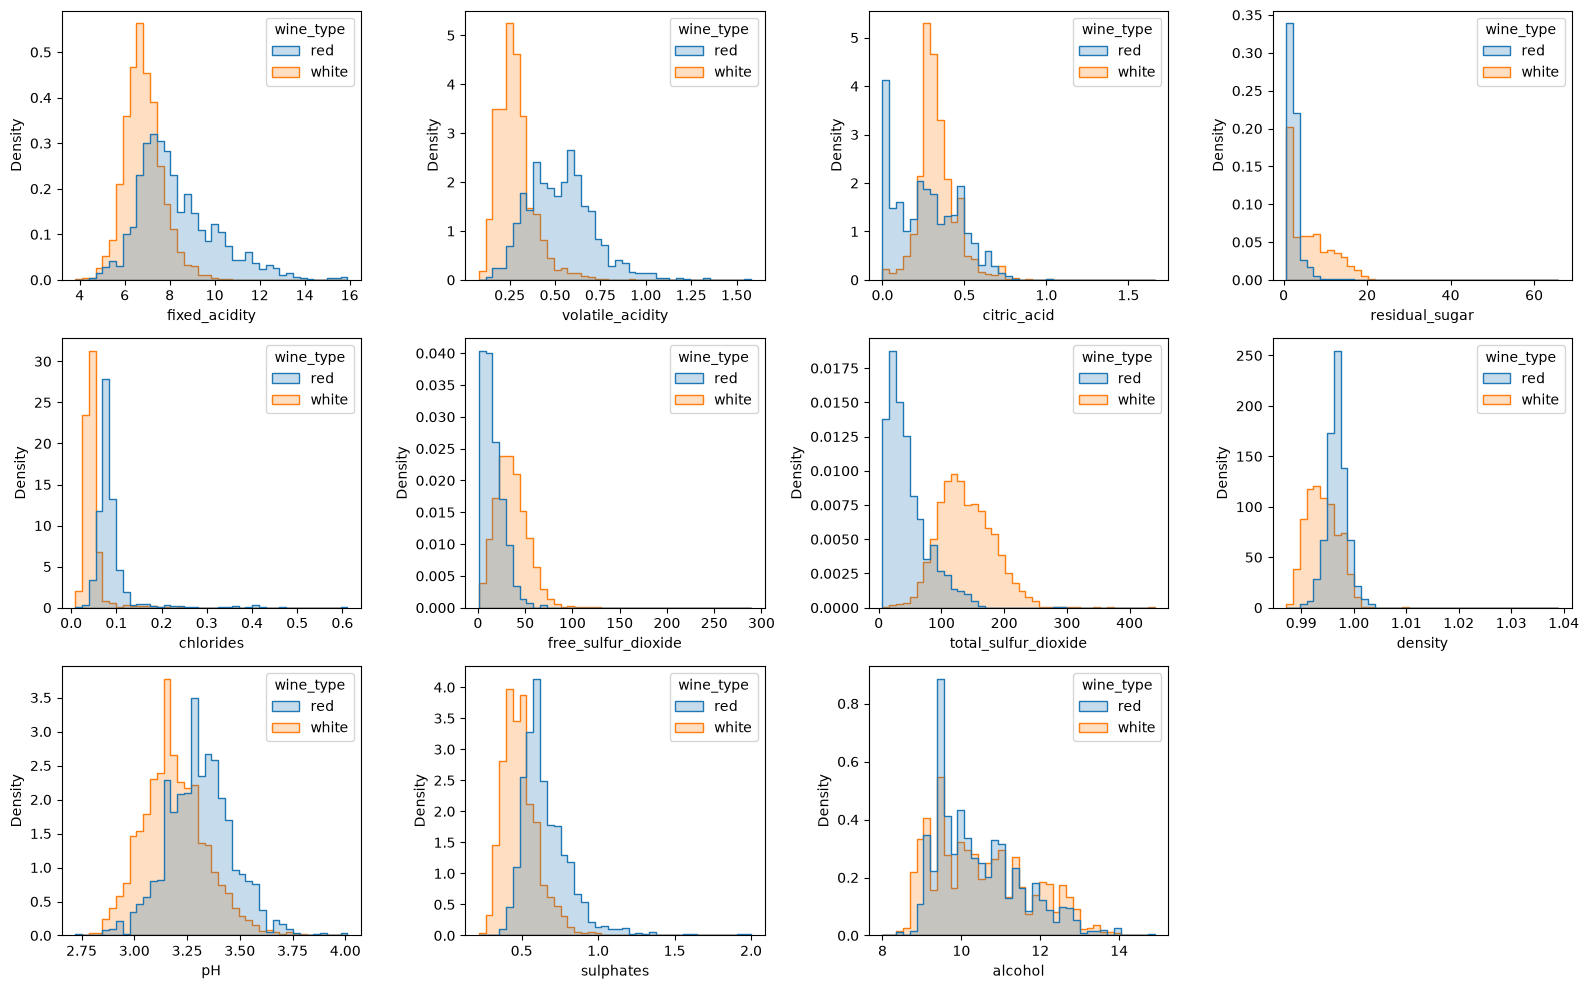

In [7]:
numerical = [c for c in df.columns if c not in ('quality', 'wine_type')]

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flat, numerical):
    sns.histplot(data=df, x=col, hue='wine_type', bins=40, ax=ax, element='step', stat='density', common_norm=False)
axes.flat[-1].axis('off')
plt.tight_layout()
plt.show()

### Target

In [8]:
df['quality'].value_counts().sort_index()

quality
3      30
4     216
5    2138
6    2836
7    1079
8     193
9       5
Name: count, dtype: int64

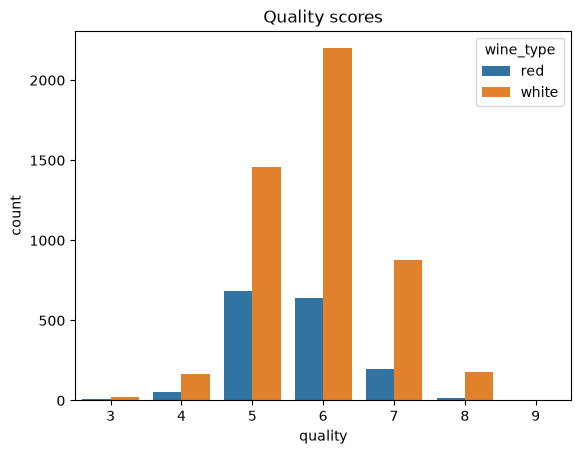

In [9]:
sns.countplot(data=df, x='quality', hue='wine_type')
plt.title('Quality scores')
plt.show()

Scores go from 3 to 9, and most wines are 5 or 6. There are very few examples at the extremes, so instead of predicting the exact score I predict if the wine is good (quality >= 7).

In [10]:
df['good'] = (df['quality'] >= 7).astype(int)

print('share of good wines:', round(df['good'].mean(), 3))
df.groupby('wine_type')['good'].agg(['mean', 'count']).round(3)

share of good wines: 0.197


,mean,count
wine_type,,
red,0.136,1599
white,0.216,4898


Around 20% are good wines, so the dataset is imbalanced. That's why I don't use accuracy: predicting "not good" for everything would already give 80%. White wines are good more often than red ones.

### Feature importance

Correlation with the target and between features:

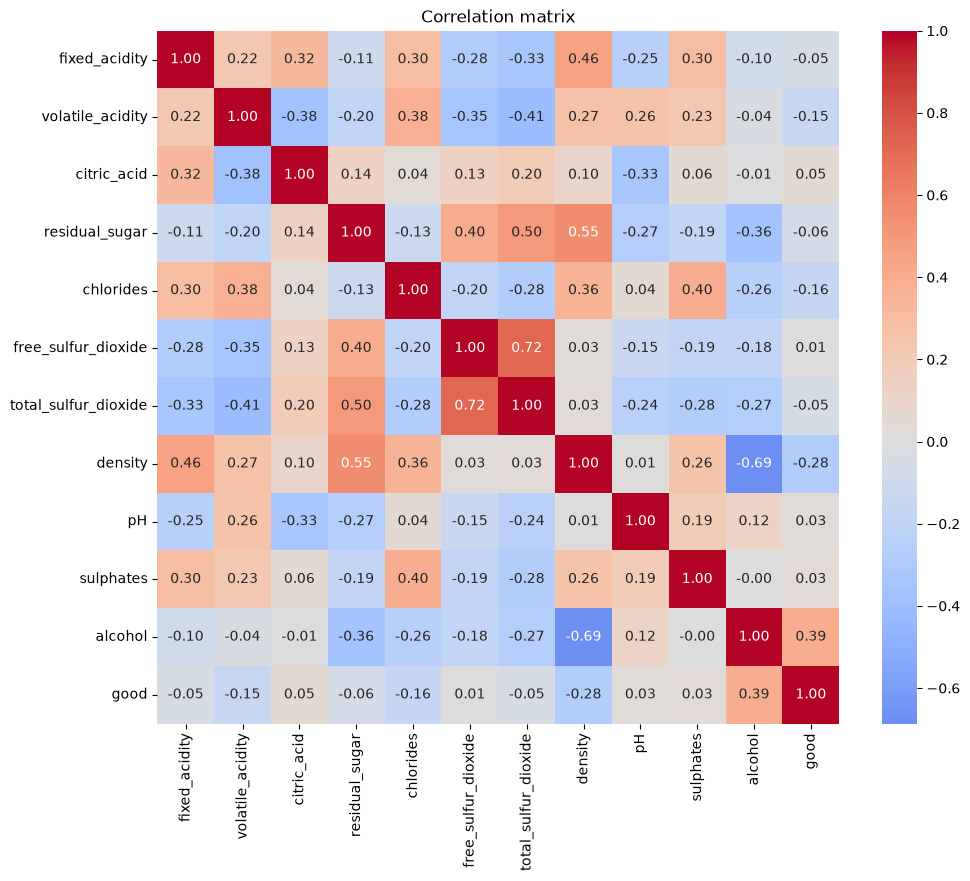

In [11]:
corr = df[numerical + ['good']].corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation matrix')
plt.show()

In [12]:
corr['good'].drop('good').sort_values(key=abs, ascending=False).round(3)

alcohol                 0.390
density                -0.275
chlorides              -0.162
volatile_acidity       -0.152
residual_sugar         -0.064
citric_acid             0.054
total_sulfur_dioxide   -0.051
fixed_acidity          -0.049
sulphates               0.034
pH                      0.028
free_sulfur_dioxide     0.015
Name: good, dtype: float64

Alcohol has the strongest relation with quality (more alcohol, better wine). Then density, but negative, and density and alcohol are also correlated with each other (-0.69). Chlorides and volatile acidity are negative too.

AUC of each feature on its own (if the AUC is below 0.5 I take 1 - AUC, like in module 4):

In [13]:
feature_auc = {}
for col in numerical:
    auc = roc_auc_score(df['good'], df[col])
    feature_auc[col] = max(auc, 1 - auc)

pd.Series(feature_auc).sort_values(ascending=False).round(3)

alcohol                 0.764
density                 0.701
chlorides               0.679
volatile_acidity        0.598
citric_acid             0.555
fixed_acidity           0.548
total_sulfur_dioxide    0.541
free_sulfur_dioxide     0.527
pH                      0.525
residual_sugar          0.524
sulphates               0.512
dtype: float64

Mutual information for `wine_type`:

In [14]:
round(mutual_info_score(df['wine_type'], df['good']), 4)

0.0041

Very low, the type alone doesn't say much, but I keep it because the model can use it together with the other features.

## 4. Train / validation / test split

60/20/20, stratified so every part has ~20% good wines. I don't use `quality` as a feature because the target comes from it.

In [15]:
features = numerical + ['wine_type']

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1, stratify=df['good'])
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1, stratify=df_full_train['good'])

y_train = df_train['good'].values
y_val = df_val['good'].values
y_test = df_test['good'].values

dicts_train = df_train[features].to_dict(orient='records')
dicts_val = df_val[features].to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(dicts_train)
X_val = dv.transform(dicts_val)

print(len(df_train), len(df_val), len(df_test))
print([round(y.mean(), 3) for y in (y_train, y_val, y_test)])

3897 1300 1300
[np.float64(0.197), np.float64(0.196), np.float64(0.197)]


## 5. Models

### Logistic regression

With standardized features. Tuning `C`.

In [16]:
lr_scores = {}
for C in [0.001, 0.01, 0.1, 1, 10]:
    lr = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=1000))
    lr.fit(X_train, y_train)
    lr_scores[C] = roc_auc_score(y_val, lr.predict_proba(X_val)[:, 1])
    print(f'C={C:<6} AUC={lr_scores[C]:.4f}')

best_lr_C = max(lr_scores, key=lr_scores.get)
print('best C:', best_lr_C)

C=0.001  AUC=0.7799
C=0.01   AUC=0.8046
C=0.1    AUC=0.8083
C=1      AUC=0.8086
C=10     AUC=0.8088
best C: 10


### Decision tree

First `max_depth`, then `min_samples_leaf`.

In [17]:
for depth in [1, 2, 3, 4, 5, 6, 8, 10, 15, None]:
    dt = DecisionTreeClassifier(max_depth=depth, random_state=1)
    dt.fit(X_train, y_train)
    auc = roc_auc_score(y_val, dt.predict_proba(X_val)[:, 1])
    print(f'max_depth={str(depth):<5} AUC={auc:.4f}')

max_depth=1     AUC=0.6904
max_depth=2     AUC=0.7430
max_depth=3     AUC=0.7905
max_depth=4     AUC=0.8155
max_depth=5     AUC=0.8205
max_depth=6     AUC=0.8325
max_depth=8     AUC=0.8246
max_depth=10    AUC=0.7790
max_depth=15    AUC=0.7456
max_depth=None  AUC=0.7364


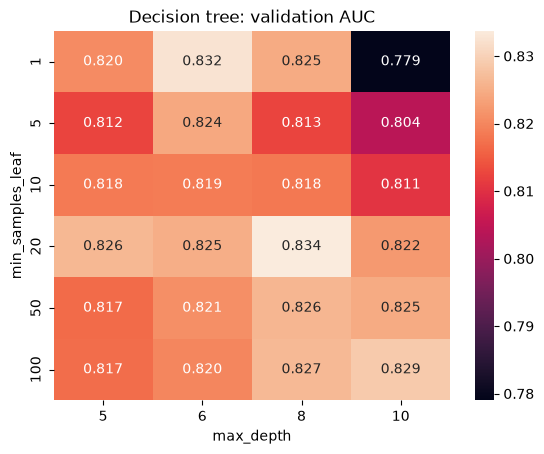

max_depth            8.000000
min_samples_leaf    20.000000
auc                  0.833718
Name: 15, dtype: float64

In [18]:
rows = []
for depth in [5, 6, 8, 10]:
    for leaf in [1, 5, 10, 20, 50, 100]:
        dt = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf, random_state=1)
        dt.fit(X_train, y_train)
        rows.append((depth, leaf, roc_auc_score(y_val, dt.predict_proba(X_val)[:, 1])))

df_dt = pd.DataFrame(rows, columns=['max_depth', 'min_samples_leaf', 'auc'])
sns.heatmap(df_dt.pivot(index='min_samples_leaf', columns='max_depth', values='auc'), annot=True, fmt='.3f')
plt.title('Decision tree: validation AUC')
plt.show()

best_dt = df_dt.loc[df_dt.auc.idxmax()]
best_dt

### Random forest

`max_depth` and `n_estimators`, then `min_samples_leaf`.

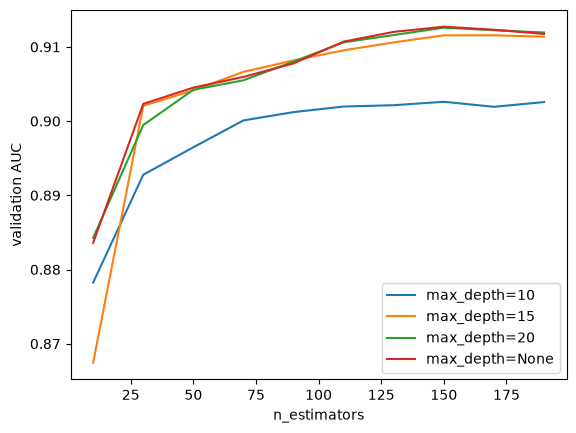

,max_depth,n_estimators,auc
37,None,150,0.912724
27,20,150,0.912592
38,None,170,0.912313
28,20,170,0.912253
36,None,130,0.912026


In [19]:
rows = []
for depth in [10, 15, 20, None]:
    for n in range(10, 201, 20):
        rf = RandomForestClassifier(n_estimators=n, max_depth=depth, random_state=1, n_jobs=-1)
        rf.fit(X_train, y_train)
        rows.append((str(depth), n, roc_auc_score(y_val, rf.predict_proba(X_val)[:, 1])))

df_rf = pd.DataFrame(rows, columns=['max_depth', 'n_estimators', 'auc'])
for depth, group in df_rf.groupby('max_depth', sort=False):
    plt.plot(group.n_estimators, group.auc, label=f'max_depth={depth}')
plt.xlabel('n_estimators')
plt.ylabel('validation AUC')
plt.legend()
plt.show()

df_rf.sort_values('auc', ascending=False).head()

In [20]:
best_rf_depth = df_rf.groupby('max_depth')['auc'].mean().idxmax()
best_rf_depth = None if best_rf_depth == 'None' else int(best_rf_depth)
print('best max_depth (by mean AUC):', best_rf_depth)

rf_leaf = {}
for leaf in [1, 3, 5, 10]:
    rf = RandomForestClassifier(n_estimators=200, max_depth=best_rf_depth, min_samples_leaf=leaf, random_state=1, n_jobs=-1)
    rf.fit(X_train, y_train)
    rf_leaf[leaf] = roc_auc_score(y_val, rf.predict_proba(X_val)[:, 1])
    print(f'min_samples_leaf={leaf:<3} AUC={rf_leaf[leaf]:.4f}')

best_rf_leaf = max(rf_leaf, key=rf_leaf.get)
print('best min_samples_leaf:', best_rf_leaf)

best max_depth (by mean AUC): None


min_samples_leaf=1   AUC=0.9123


min_samples_leaf=3   AUC=0.9041


min_samples_leaf=5   AUC=0.8977


min_samples_leaf=10  AUC=0.8897
best min_samples_leaf: 1


### XGBoost

Tuning eta, then `max_depth`, then `min_child_weight`, looking at the validation AUC in each round.

eta=0.3   best AUC=0.8918 at round 78


eta=0.1   best AUC=0.8928 at round 297


eta=0.05  best AUC=0.8910 at round 279


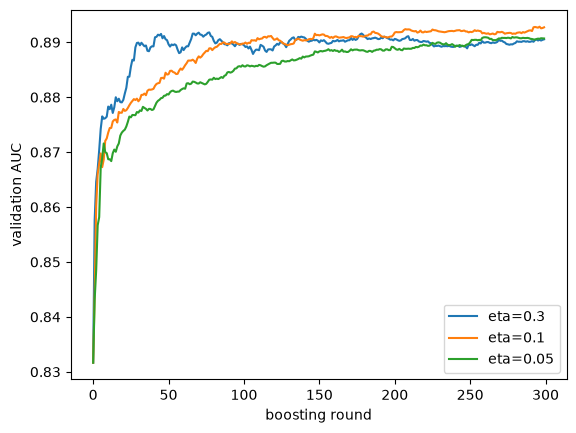

best eta: 0.1


In [21]:
def xgb_curve(**params):
    model = XGBClassifier(n_estimators=300, eval_metric='auc', random_state=1, n_jobs=8, **params)
    model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
    return np.array(model.evals_result()['validation_0']['auc'])


eta_results = {}
for eta in [0.3, 0.1, 0.05]:
    curve = xgb_curve(learning_rate=eta, max_depth=6, min_child_weight=1)
    eta_results[eta] = curve.max()
    plt.plot(curve, label=f'eta={eta}')
    print(f'eta={eta:<5} best AUC={curve.max():.4f} at round {curve.argmax() + 1}')
plt.xlabel('boosting round')
plt.ylabel('validation AUC')
plt.legend()
plt.show()

best_eta = max(eta_results, key=eta_results.get)
print('best eta:', best_eta)

In [22]:
depth_results = {}
for depth in [3, 4, 6, 8, 10]:
    curve = xgb_curve(learning_rate=best_eta, max_depth=depth, min_child_weight=1)
    depth_results[depth] = curve.max()
    print(f'max_depth={depth:<3} best AUC={curve.max():.4f} at round {curve.argmax() + 1}')

best_xgb_depth = max(depth_results, key=depth_results.get)
print('best max_depth:', best_xgb_depth)

max_depth=3   best AUC=0.8761 at round 265


max_depth=4   best AUC=0.8849 at round 215


max_depth=6   best AUC=0.8928 at round 297


max_depth=8   best AUC=0.8905 at round 230


max_depth=10  best AUC=0.8989 at round 142
best max_depth: 10


In [23]:
mcw_results = {}
for mcw in [1, 5, 10, 30]:
    curve = xgb_curve(learning_rate=best_eta, max_depth=best_xgb_depth, min_child_weight=mcw)
    mcw_results[mcw] = (curve.max(), int(curve.argmax()) + 1)
    print(f'min_child_weight={mcw:<3} best AUC={curve.max():.4f} at round {curve.argmax() + 1}')

XGB_MCW = max(mcw_results, key=lambda k: mcw_results[k][0])
XGB_ROUNDS = mcw_results[XGB_MCW][1]
print('best min_child_weight:', XGB_MCW, '| rounds:', XGB_ROUNDS)

min_child_weight=1   best AUC=0.8989 at round 142


min_child_weight=5   best AUC=0.8915 at round 290


min_child_weight=10  best AUC=0.8888 at round 260


min_child_weight=30  best AUC=0.8716 at round 137
best min_child_weight: 1 | rounds: 142


## 6. Comparing the models

Best version of each model on the validation set:

In [24]:
final_candidates = {
    'logistic_regression': make_pipeline(StandardScaler(), LogisticRegression(C=best_lr_C, max_iter=1000)),
    'decision_tree': DecisionTreeClassifier(max_depth=int(best_dt.max_depth), min_samples_leaf=int(best_dt.min_samples_leaf), random_state=1),
    'random_forest': RandomForestClassifier(n_estimators=200, max_depth=best_rf_depth, min_samples_leaf=best_rf_leaf, random_state=1, n_jobs=-1),
    'xgboost': XGBClassifier(n_estimators=XGB_ROUNDS, learning_rate=best_eta, max_depth=best_xgb_depth, min_child_weight=XGB_MCW, random_state=1, n_jobs=8),
}

val_auc = {}
for name, model in final_candidates.items():
    model.fit(X_train, y_train)
    val_auc[name] = roc_auc_score(y_val, model.predict_proba(X_val)[:, 1])

pd.Series(val_auc).sort_values(ascending=False).round(4)

random_forest          0.9123
xgboost                0.8989
decision_tree          0.8337
logistic_regression    0.8088
dtype: float64

## 7. Final model

I retrain the best model on train + validation and check it once on the test set.

In [25]:
best_name = max(val_auc, key=val_auc.get)
print('selected model:', best_name)

dv_full = DictVectorizer(sparse=False)
X_full_train = dv_full.fit_transform(df_full_train[features].to_dict(orient='records'))
X_test = dv_full.transform(df_test[features].to_dict(orient='records'))

final_model = final_candidates[best_name]
final_model.fit(X_full_train, df_full_train['good'].values)

y_pred = final_model.predict_proba(X_test)[:, 1]
print('test AUC:', round(roc_auc_score(y_test, y_pred), 4))
print('validation AUC:', round(val_auc[best_name], 4))

selected model: random_forest


test AUC: 0.9153
validation AUC: 0.9123


In [26]:
for t in [0.3, 0.4, 0.5, 0.6]:
    decision = y_pred >= t
    print(f'threshold={t}: precision={precision_score(y_test, decision):.3f}  recall={recall_score(y_test, decision):.3f}')

threshold=0.3: precision=0.571  recall=0.785
threshold=0.4: precision=0.681  recall=0.691
threshold=0.5: precision=0.764  recall=0.594
threshold=0.6: precision=0.857  recall=0.516


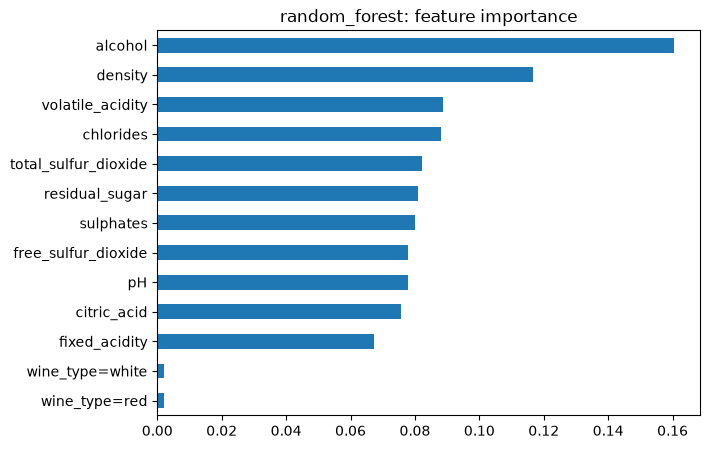

In [27]:
importance = pd.Series(final_model.feature_importances_, index=dv_full.get_feature_names_out())
importance.sort_values().plot.barh(figsize=(7, 5), title=f'{best_name}: feature importance')
plt.show()

## 8. Conclusions

- Random forest and XGBoost are much better than logistic regression and a single tree, probably because the relation between the measurements and the quality is not linear.
- The test AUC is very close to the validation one, so the model didn't just get lucky on the validation set.
- Alcohol is the most important feature, same as in the EDA.
- The threshold depends on what the winery wants: with a low threshold it finds most of the good wines, with a high one it finds fewer but it's right more often.

The training of the final model is in `train.py` and the web service in `predict.py`.